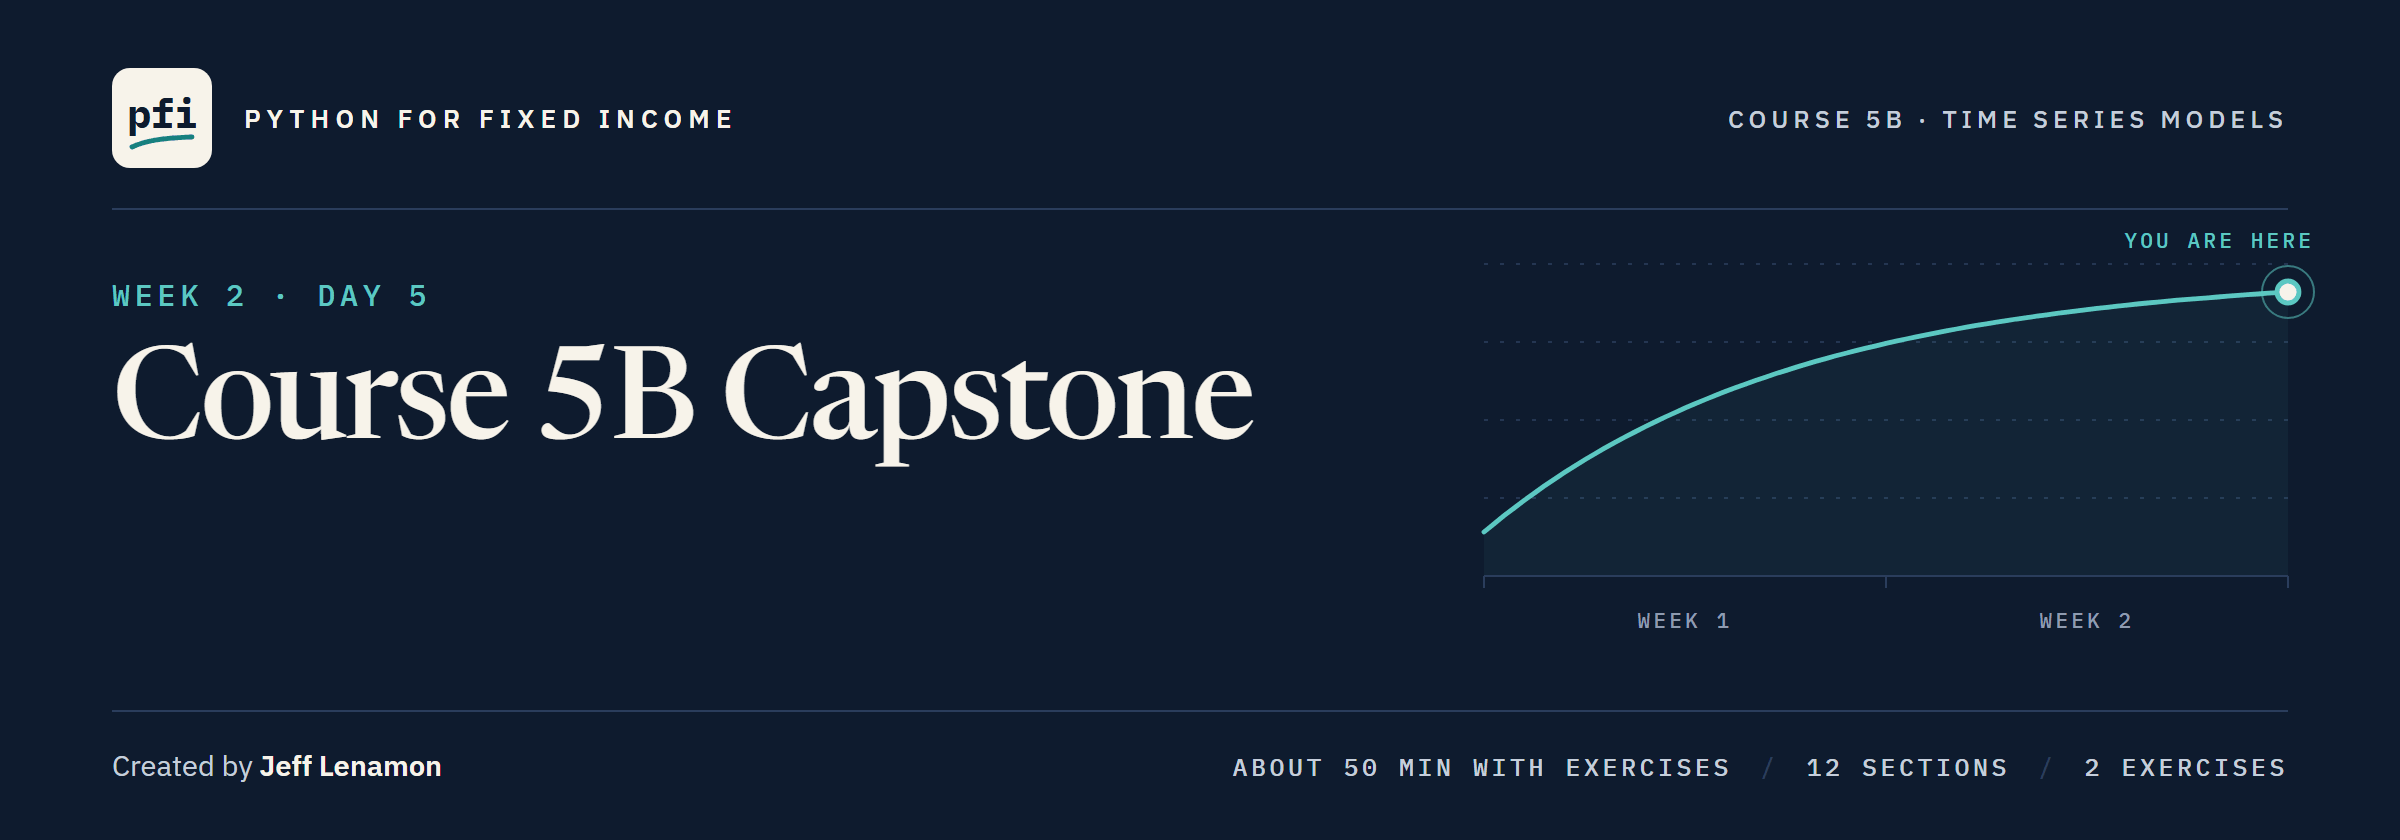

# Course 5B Capstone

Week 2, Day 5. Run the whole course on a copy you have never seen, choose on the development years, then open the held-out years once.

**Data:** `treasury_par_yields.csv`, 2,940 days of U.S. Treasury par yields, 2015-01-02 to 2026-10-02: **real**, U.S. Department of the Treasury, public domain.

**Data:** `course3_synthetic_spreads.csv`, 2,940 daily investment grade and high yield spreads in bp, one per date of the Treasury file: **synthetic**, invented for Course 3, not ICE, Moody's, or any index.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05b_time_series/week2/day5/course5b_capstone.ipynb)

# Problem Statement

## Business Context

A colleague hands you a copy of the 2 Yr and 10 Yr yields and a synthetic HY spread, in bp, with blank days and a few wrong prints.
From it you build the 2s10s slope and the HY, and ask the course's two questions of each.
Does any model of the change get closer than the last value carried forward?
Does any rule for the size of a change get closer than a constant?
Every output is a value for a date inside the file, from the dates before it, never a forecast of rates or spreads.
The work is yours: each question has an empty cell and a `check()` line.

## Objectives

Repair a dated copy with a log, and test and describe both series.
Score models of the change and of its size over Day 2's folds, and choose by a rule written first.
Open the held-out years once, score every model there, and say where the models miss.

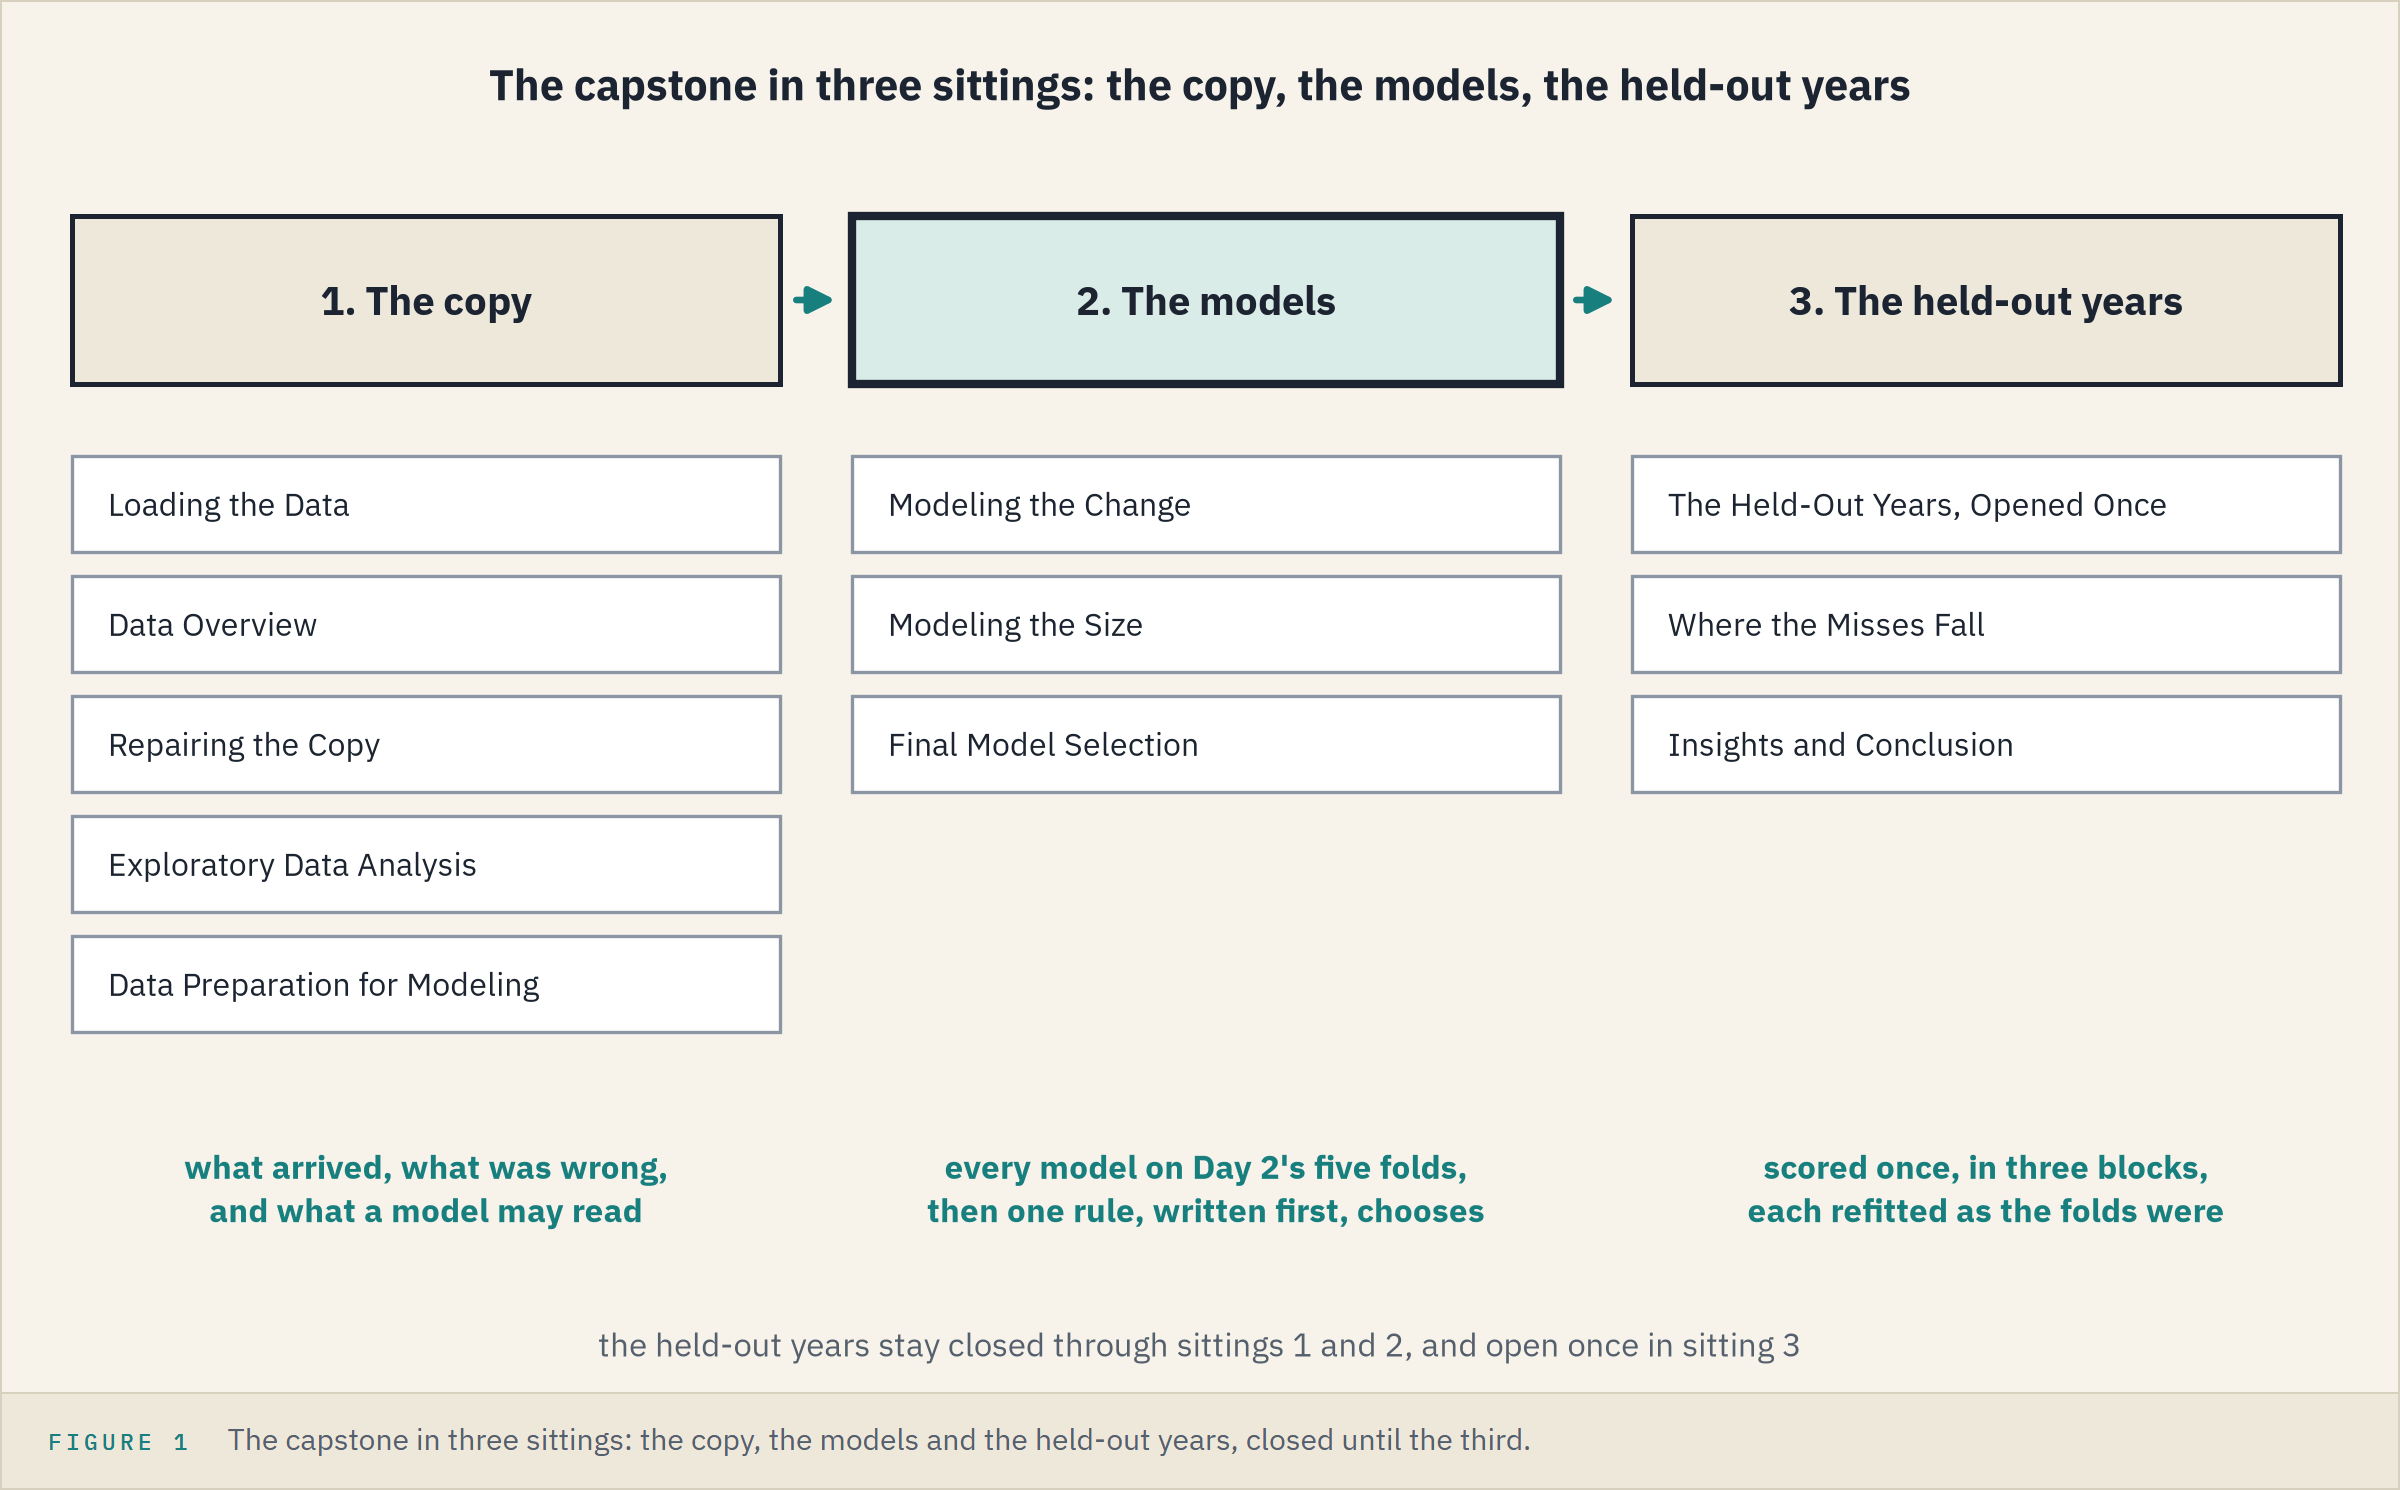

## Data Dictionary

`treasury_par_yields.csv`, one row per trading day:

1. `date`: the trading day, the index
2. `2 Yr`, `10 Yr`: par yields, in percent

`course3_synthetic_spreads.csv`, the same dates:

3. `hy_spread_bp`: the synthetic HY spread, in bp
4. `ig_spread_bp`: the synthetic IG spread, in bp, for Day 8's lag features only

Made here, in bp: `truth` and `published` (the true values and the copy), `second_feed`, and Day 2's five series from the repaired copy.

## Your Route Through Day 5

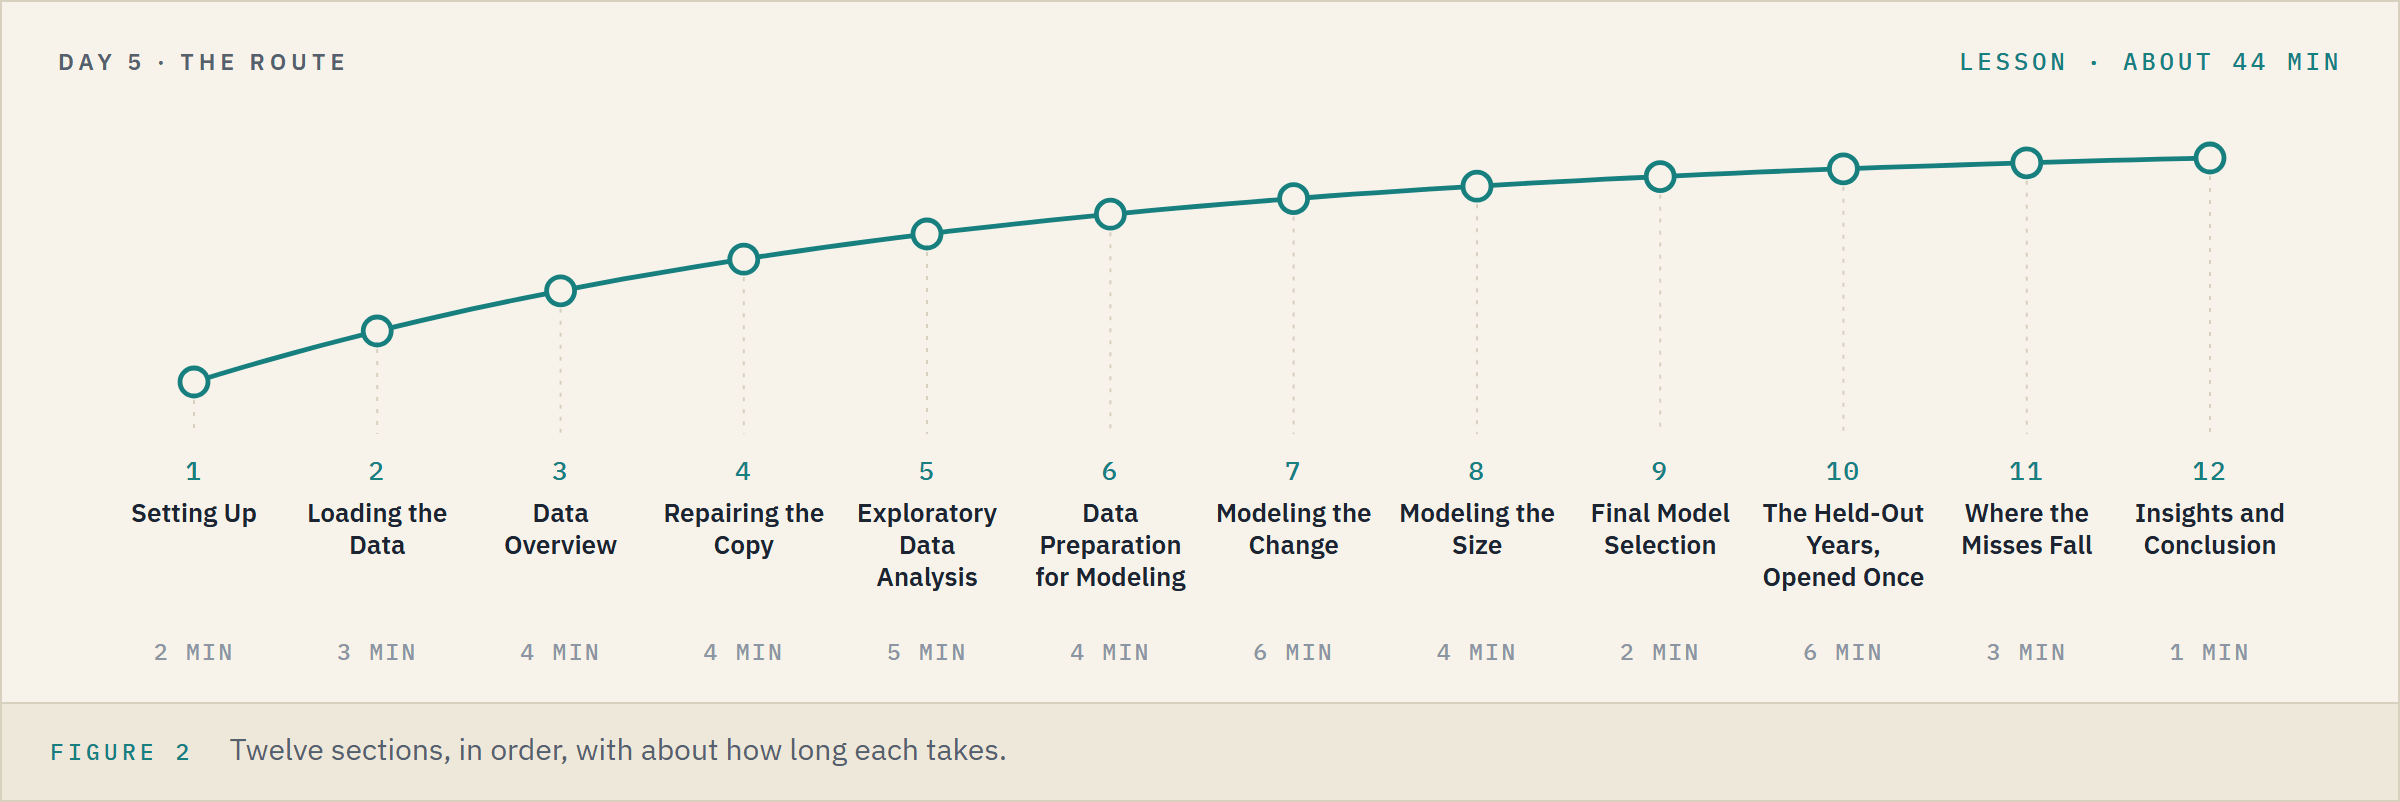

**Time.** About 44 minutes for the lesson, then about 6 for the two exercises.

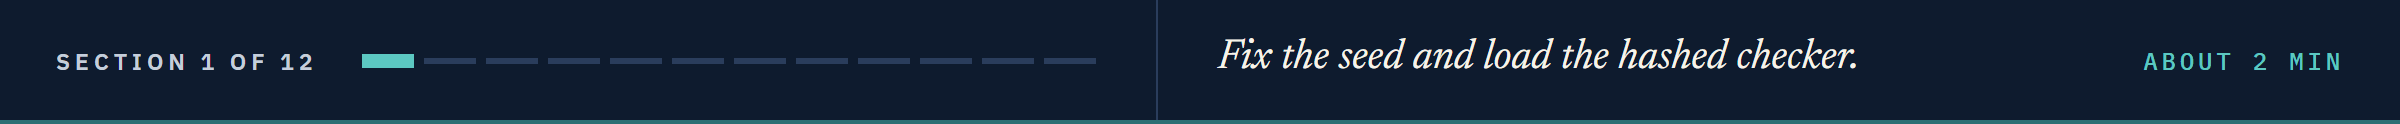

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data, and the normal curve
import numpy as np
import pandas as pd
from scipy import stats

# to draw charts
import matplotlib.pyplot as plt
import seaborn as sns

# Day 2's folds and score, Day 3's two tests, Day 4's autocorrelation and Ljung-Box
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import mean_absolute_error
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from arch.unitroot import KPSS

# Day 5's ARIMA, Day 6's smoothing, Day 7's GARCH and Day 8's LightGBM
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from arch import arch_model
from lightgbm import LGBMRegressor

# to hold an optimiser to one thread, so its last digits are the same on every run, and the one warning a cell may meet by name
from threadpoolctl import threadpool_limits
import warnings
from statsmodels.tools.sm_exceptions import EstimationWarning

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:.4f}".format)

## The Answer Checker

`check()` compares a fingerprint of each answer with a stored one, so no answer is on the page.
A number is rounded to the places its question asks for.

In [3]:
# check() compares a fingerprint of your answer with a stored one, so no answer is written on the page
import hashlib


def check(label, answer, code, places=None):
    if answer is ...:
        print(label + ": not attempted yet")
        return
    # a number is rounded to the places the question asks for, so 0.66241 and 0.6624 read the same
    if places is not None:
        answer = round(float(answer), places)
    text = label + "|" + str(answer).strip().lower()
    # hashlib.sha256() makes a fingerprint that cannot be turned back into the answer;
    # .encode() turns the text into bytes for it, and .hexdigest() writes it as letters and digits
    if hashlib.sha256(text.encode()).hexdigest()[:12] == code:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have " + str(answer))

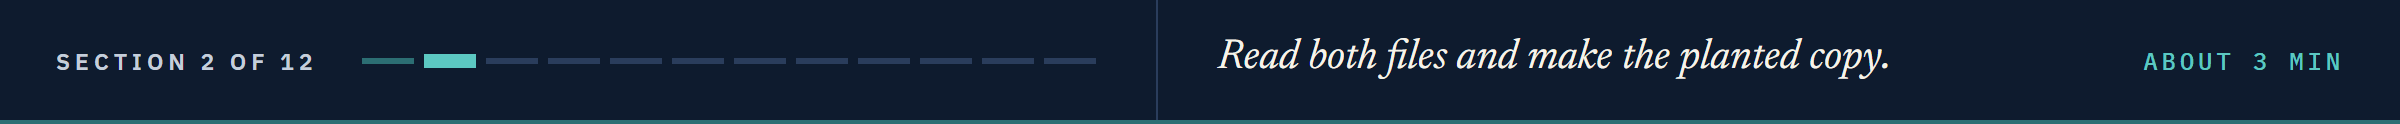

# Loading the Data

## The Two Files and the Cut

Day 2's cut stands: every choice is made on the years to 2022-12-30.
This is the one notebook that opens the held-out years, once, after every choice is made.

In [4]:
# the Treasury par yields (percent) and the synthetic spreads (bp): one row per trading day
yields = pd.read_csv(DATA + "treasury_par_yields.csv", parse_dates=["date"], index_col="date")
spreads = pd.read_csv(DATA + "course3_synthetic_spreads.csv", parse_dates=["date"], index_col="date")

# Day 2's cut: the development years only; the held-out dates are counted, never read
CUT = "2022-12-30"
development = yields.loc[:CUT]
print("Development:", len(development), "dates | held out:", (yields.index > CUT).sum(), "dates, closed for now")

Development: 2001 dates | held out: 939 dates, closed for now


## The Copy You Were Handed

The copy is made from the true values, with problems planted for the lesson by the seeded generator, as on Day 1.
The true values stay aside as `truth`, to check the repair; the files have none of these problems.

In [5]:
# the true development values in bp: the 2 Yr and 10 Yr (percent times 100), the HY as stored
truth = pd.DataFrame({"2 Yr": (development["2 Yr"] * 100).round(2), "10 Yr": (development["10 Yr"] * 100).round(2),
                      "HY": spreads.loc[:CUT, "hy_spread_bp"]})

# four blank cells in each column, from one seeded generator
rng = np.random.default_rng(SEED)
published = truth.copy()
for column in published.columns:
    rows = np.sort(rng.choice(np.arange(10, len(published) - 10, 7), size=4, replace=False))
    published.iloc[rows, published.columns.get_loc(column)] = np.nan

In [6]:
# one wrong print in each column, a slipped decimal, on a date of the given year with a value on both sides
wrong_prints = {"2 Yr": (2017, 10), "10 Yr": (2019, 0.1), "HY": (2021, 10)}
wrong_dates = {}
for column, (year, factor) in wrong_prints.items():
    present = published[column].notna().to_numpy()
    safe = present[1:-1] & present[:-2] & present[2:] & (published.index[1:-1].year == year)
    wrong_dates[column] = published.index[int(rng.choice(np.flatnonzero(safe) + 1))]
    published.loc[wrong_dates[column], column] = truth.loc[wrong_dates[column], column] * factor

In [7]:
# a second feed: the true value of each wrong print and of each column's first blank, with its source
blank_first = {column: published.index[published[column].isna()][0] for column in published.columns}
feed_rows = []
for column in published.columns:
    for date in (wrong_dates[column], blank_first[column]):
        feed_rows.append((date, column, truth.loc[date, column], "second feed"))
second_feed = pd.DataFrame(feed_rows, columns=["date", "column", "value", "source"])
print("The copy:", published.shape, "| the second feed:", len(second_feed), "cells")

The copy: (2001, 3) | the second feed: 6 cells


**You work on `published` as if it had just arrived, and read `truth` only to score a repair.**

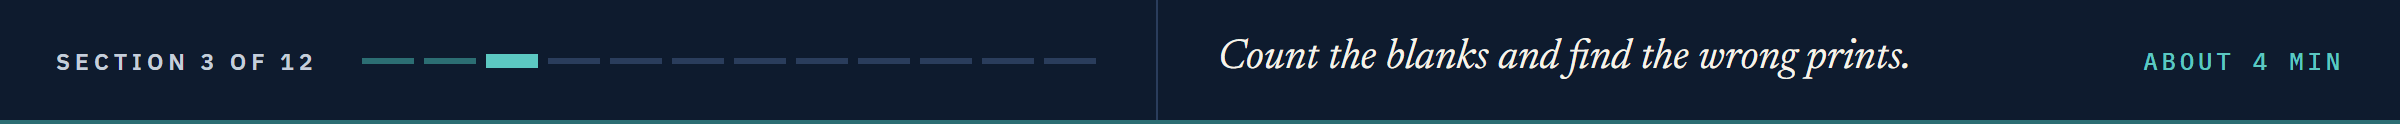

# Data Overview

## Blanks

Q. How many cells of `published` are blank, and how many rows long is the longest run of blanks in any column? Store them in `q1_blanks` and `q1_longest`.

In [8]:
# your code here
q1_blanks = ...
q1_longest = ...

In [9]:
check("Q1 blank cells", q1_blanks, "41a4fe192f71", places=0)
check("Q1 longest run", q1_longest, "414d04d29440", places=0)

Q1 blank cells: not attempted yet
Q1 longest run: not attempted yet


## Wrong Prints

The copy is in bp, so Day 1's jump-and-back rule needs no `* 100`.

Q. How many cells does it flag in `published`, and in `truth`? Store them in `q2_flags` and `q2_truth_flags`.

Q. The suspect is the row before each flag. How many suspects does `second_feed` cover? Store it in `q2_covered`.

In [10]:
# your code here
q2_flags = ...
q2_truth_flags = ...

In [11]:
# your code here
q2_covered = ...

In [12]:
check("Q2 flags", q2_flags, "14e88bf4a331", places=0)
check("Q2 flags in the true values", q2_truth_flags, "32870e4bcea2", places=0)
check("Q2 suspects covered", q2_covered, "543a4044d9a9", places=0)

Q2 flags: not attempted yet
Q2 flags in the true values: not attempted yet
Q2 suspects covered: not attempted yet


### The Three Wrong Prints

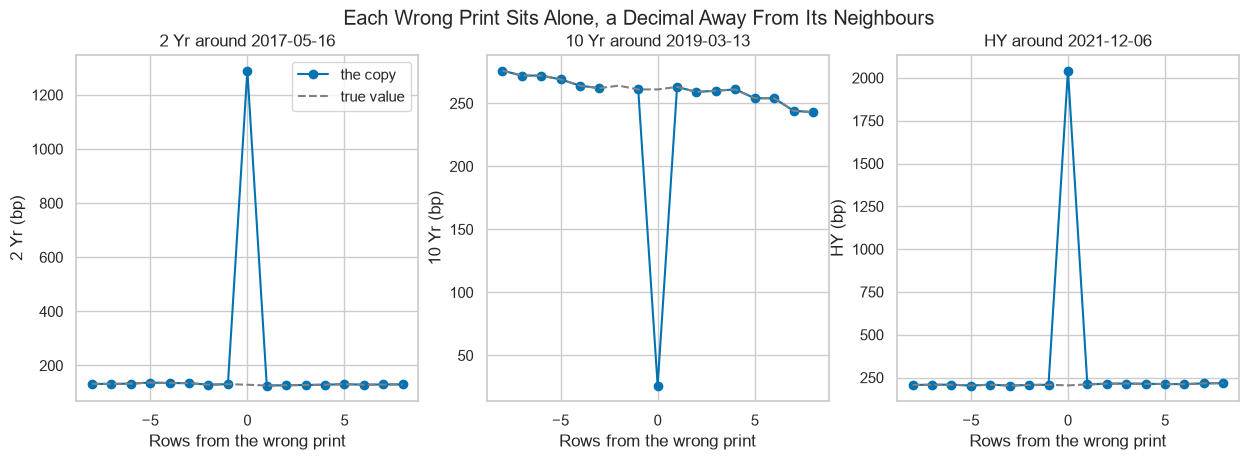

In [13]:
# each planted wrong print with eight rows either side: the copy as handed over, the true value dashed
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))
for ax, (column, date) in zip(axes, wrong_dates.items()):
    at = published.index.get_loc(date)
    ax.plot(range(-8, 9), published[column].iloc[at - 8:at + 9], marker="o", label="the copy")
    ax.plot(range(-8, 9), truth[column].iloc[at - 8:at + 9], color="gray", linestyle="--", label="true value")
    ax.set(title=column + " around " + str(date.date()), xlabel="Rows from the wrong print", ylabel=column + " (bp)")
axes[0].legend()
fig.suptitle("Each Wrong Print Sits Alone, a Decimal Away From Its Neighbours")
plt.show()

**Twelve blanks and three wrong prints, and a second feed to check them against.**

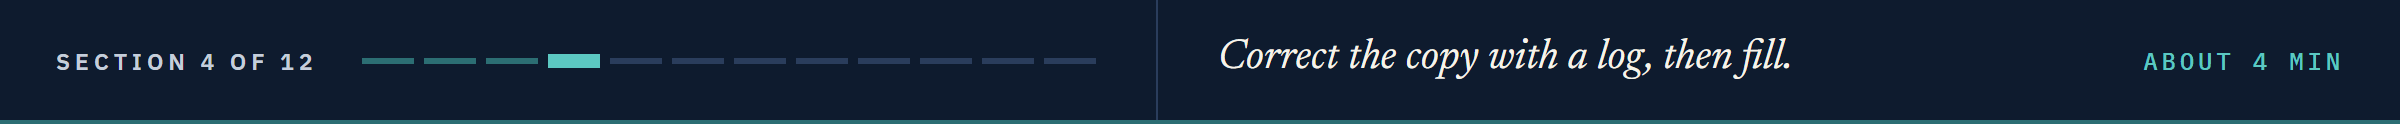

# Repairing the Copy

## The Corrections Table and the Log

Q. Write `second_feed` into a copy of `published` with Day 1's loop, as `fixed`, with the log as `change_log`. Store the cells changed and the blanks left in `q3_changed` and `q3_left`.

In [14]:
# your code here
q3_changed = ...
q3_left = ...

In [15]:
check("Q3 cells changed", q3_changed, "2e5361fd5fd7", places=0)
check("Q3 blanks left", q3_left, "374b8f5865ad", places=0)

Q3 cells changed: not attempted yet
Q3 blanks left: not attempted yet


**Predict 1**

The blanks left are single days, so `fixed.ffill(limit=1)` fills each with the quote from the row before.

Q. After that fill, how many of the 6,003 cells will differ from `truth`, and by at most how many bp? Write down two numbers.

## A One-Row Fill

Q. Fill `fixed` that way as `repaired`. Store the blanks left, the cells that differ from `truth`, and the largest difference in bp in `q4_left`, `q4_differ` and `q4_largest` (1 decimal).

In [16]:
# your code here
q4_left = ...
q4_differ = ...
q4_largest = ...

In [17]:
check("Q4 blanks left", q4_left, "11f2e58e92ca", places=0)
check("Q4 cells that differ", q4_differ, "43661d386b53", places=0)
check("Q4 largest difference", q4_largest, "fa05613bbc26", places=1)

Q4 blanks left: not attempted yet
Q4 cells that differ: not attempted yet
Q4 largest difference: not attempted yet


## The Two Series

Q. Build `levels`, Day 2's five series, from `repaired` (the `IG` from `spreads`), then `changes` and `SERIES = ["2s10s", "HY"]`. Store the 2s10s's mean level (2 decimals) and the dates on which each series did not change in `q5_mean`, `q5_flat_2s10s` and `q5_flat_hy`.

In [18]:
# your code here
q5_mean = ...
q5_flat_2s10s = ...
q5_flat_hy = ...

In [19]:
check("Q5 mean 2s10s", q5_mean, "76304942f3ce", places=2)
check("Q5 dates with no change, 2s10s", q5_flat_2s10s, "f01a926ac536", places=0)
check("Q5 dates with no change, HY", q5_flat_hy, "794f422665dd", places=0)

Q5 mean 2s10s: not attempted yet
Q5 dates with no change, 2s10s: not attempted yet
Q5 dates with no change, HY: not attempted yet


**Every change to the copy is in the log, and the fill is capped at one row.**

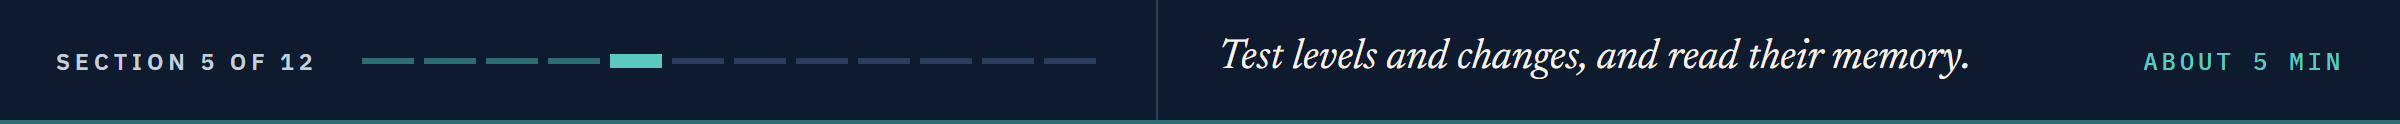

# Exploratory Data Analysis

## Eight Years of Moves

Day 7's **horizon chart**, on the average size of the 20 changes up to each date, in units of its eight-year average.
It reads the true values, so it runs before your cells are filled.

In [20]:
# the 2s10s and the HY from the true values; the average size of the 20 changes up to each date, in units of its mean
true_pair = pd.DataFrame({"2s10s": truth["10 Yr"] - truth["2 Yr"], "HY": truth["HY"]})
busy = true_pair.diff().abs().rolling(20).mean()
busy = busy / busy.mean()
print("Busiest 20 dates end on", busy.idxmax().dt.date.to_dict(), "at", busy.max().round(2).to_dict(), "times the average")

Busiest 20 dates end on {'2s10s': datetime.date(2020, 3, 25), 'HY': datetime.date(2021, 7, 23)} at {'2s10s': 2.83, 'HY': 3.49} times the average


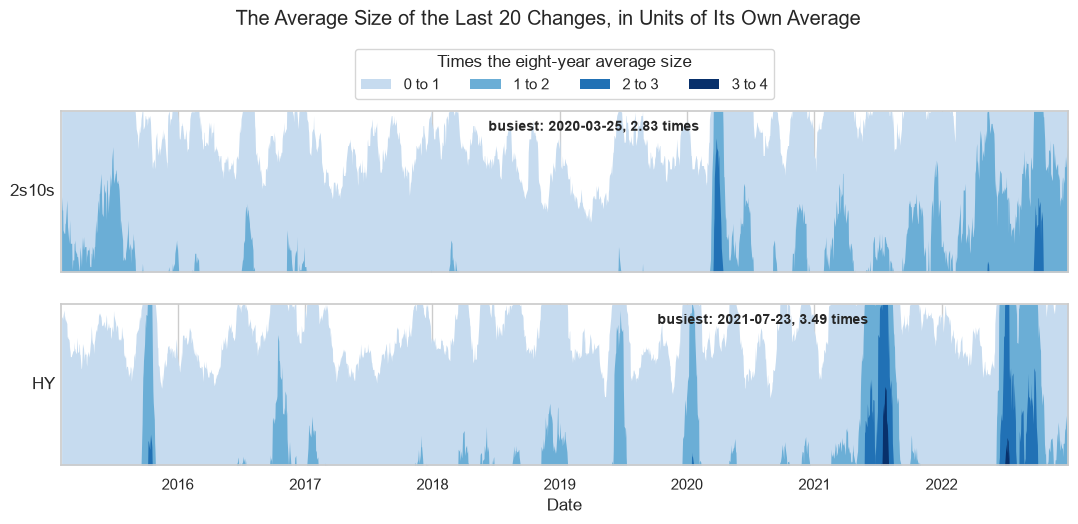

In [21]:
# each series folded into bands of one unit, darker for a busier stretch; its busiest date marked
fig, axes = plt.subplots(2, 1, figsize=(13, 4.6), sharex=True)
for ax, name in zip(axes, busy.columns):
    for band, shade in enumerate(["#c6dbef", "#6baed6", "#2171b5", "#08306b"]):
        ax.fill_between(busy.index, 0, (busy[name] - band).clip(0, 1), color=shade, linewidth=0, label=f"{band} to {band + 1}")
    peak = busy[name].idxmax()
    ax.annotate(f"busiest: {peak.date()}, {busy[name].max():.2f} times", (peak, 0.9), xytext=(-12, 0), textcoords="offset points",
                ha="right", va="center", fontsize=10, weight="bold")
    ax.set(ylim=(0, 1), yticks=[], xlim=(busy.index[19], busy.index[-1]))
    ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=12)
axes[0].legend(title="Times the eight-year average size", ncols=4, loc="lower center", bbox_to_anchor=(0.5, 1.03))
axes[1].set_xlabel("Date")
fig.suptitle("The Average Size of the Last 20 Changes, in Units of Its Own Average", y=1.1)
plt.show()

The 2s10s's busiest 20 changes end on 2020-03-25, at 2.83 times its average, and it is busy again through 2022.

The synthetic HY's busiest stretches, mid-2021 and mid-2022, are its own, peaking at 3.49 times.

Calm years stay in the palest band for months at a time.

**The size of a change comes in stretches; the change itself is tested next.**

## Level or Change

Day 3's two tests: `adfuller(values, result_object=True)` and arch's `KPSS(values, lags=20)`.

Q. Run both on each series' level and change, in a table `tests`. Store the 2s10s level's ADF p-value, the HY level's KPSS p-value and the 2s10s change's KPSS p-value in `q6_level_adf`, `q6_hy_kpss` and `q6_change_kpss` (4 decimals).

Q. Draw Day 3's p-value map: each p-value a dot on a log axis, 0.05 marked.

In [22]:
# your code here
q6_level_adf = ...
q6_hy_kpss = ...
q6_change_kpss = ...

# then your chart

In [23]:
check("Q6 2s10s level ADF p-value", q6_level_adf, "22e492312fca", places=4)
check("Q6 HY level KPSS p-value", q6_hy_kpss, "17d24ee12316", places=4)
check("Q6 2s10s change KPSS p-value", q6_change_kpss, "b0e7d5845fb9", places=4)

Q6 2s10s level ADF p-value: not attempted yet
Q6 HY level KPSS p-value: not attempted yet
Q6 2s10s change KPSS p-value: not attempted yet


**Both levels read as a unit root and both changes as stationary, so every model works on changes.**

## Memory in the Change and in Its Size

Day 4's band is 1.96 / sqrt(n).

Q. For each change and its square, count the ACF bars outside the band at lags 1 to 40 and read Ljung-Box at 10 lags, in a table `memory`. Store the band, the 2s10s change's bars outside, and the HY change's Ljung-Box p-value in `q7_band`, `q7_outside` and `q7_hy_p` (4 decimals).

Q. Draw the four ACFs as bars, the band shaded.

In [24]:
# your code here
q7_band = ...
q7_outside = ...
q7_hy_p = ...

# then your chart

In [25]:
check("Q7 band", q7_band, "afb96cfa9513", places=4)
check("Q7 2s10s change bars outside", q7_outside, "b69d4b286772", places=0)
check("Q7 HY change Ljung-Box p-value", q7_hy_p, "d31b0e545e79", places=4)

Q7 band: not attempted yet
Q7 2s10s change bars outside: not attempted yet
Q7 HY change Ljung-Box p-value: not attempted yet


**No memory a test sees in the sign of a change; plenty in its size.**

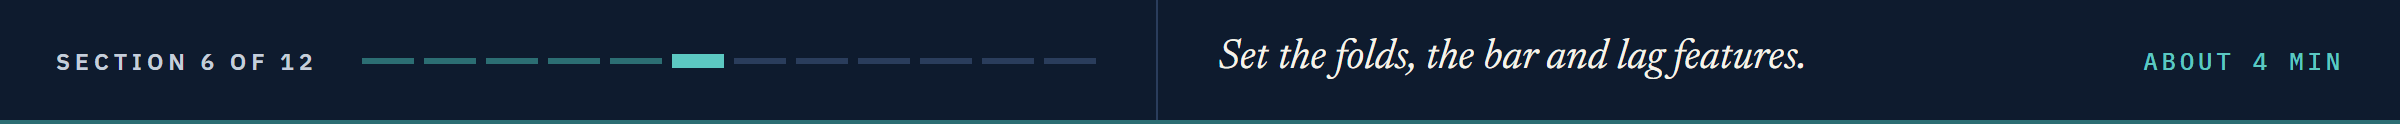

# Data Preparation for Modeling

## Day 2's Folds and the Bar

Q. Make Day 2's five `folds`, and keep the last value's MAE per fold and series in a table `bar`. Store the 2s10s's average and fold range (largest less smallest), and the HY's average, in `q8_bar`, `q8_range` and `q8_hy_bar` (4 decimals).

In [26]:
# your code here
q8_bar = ...
q8_range = ...
q8_hy_bar = ...

In [27]:
check("Q8 2s10s bar", q8_bar, "750983ea1481", places=4)
check("Q8 2s10s fold range", q8_range, "136d1c7adc6d", places=4)
check("Q8 HY bar", q8_hy_bar, "870a70af2faa", places=4)

Q8 2s10s bar: not attempted yet
Q8 2s10s fold range: not attempted yet
Q8 HY bar: not attempted yet


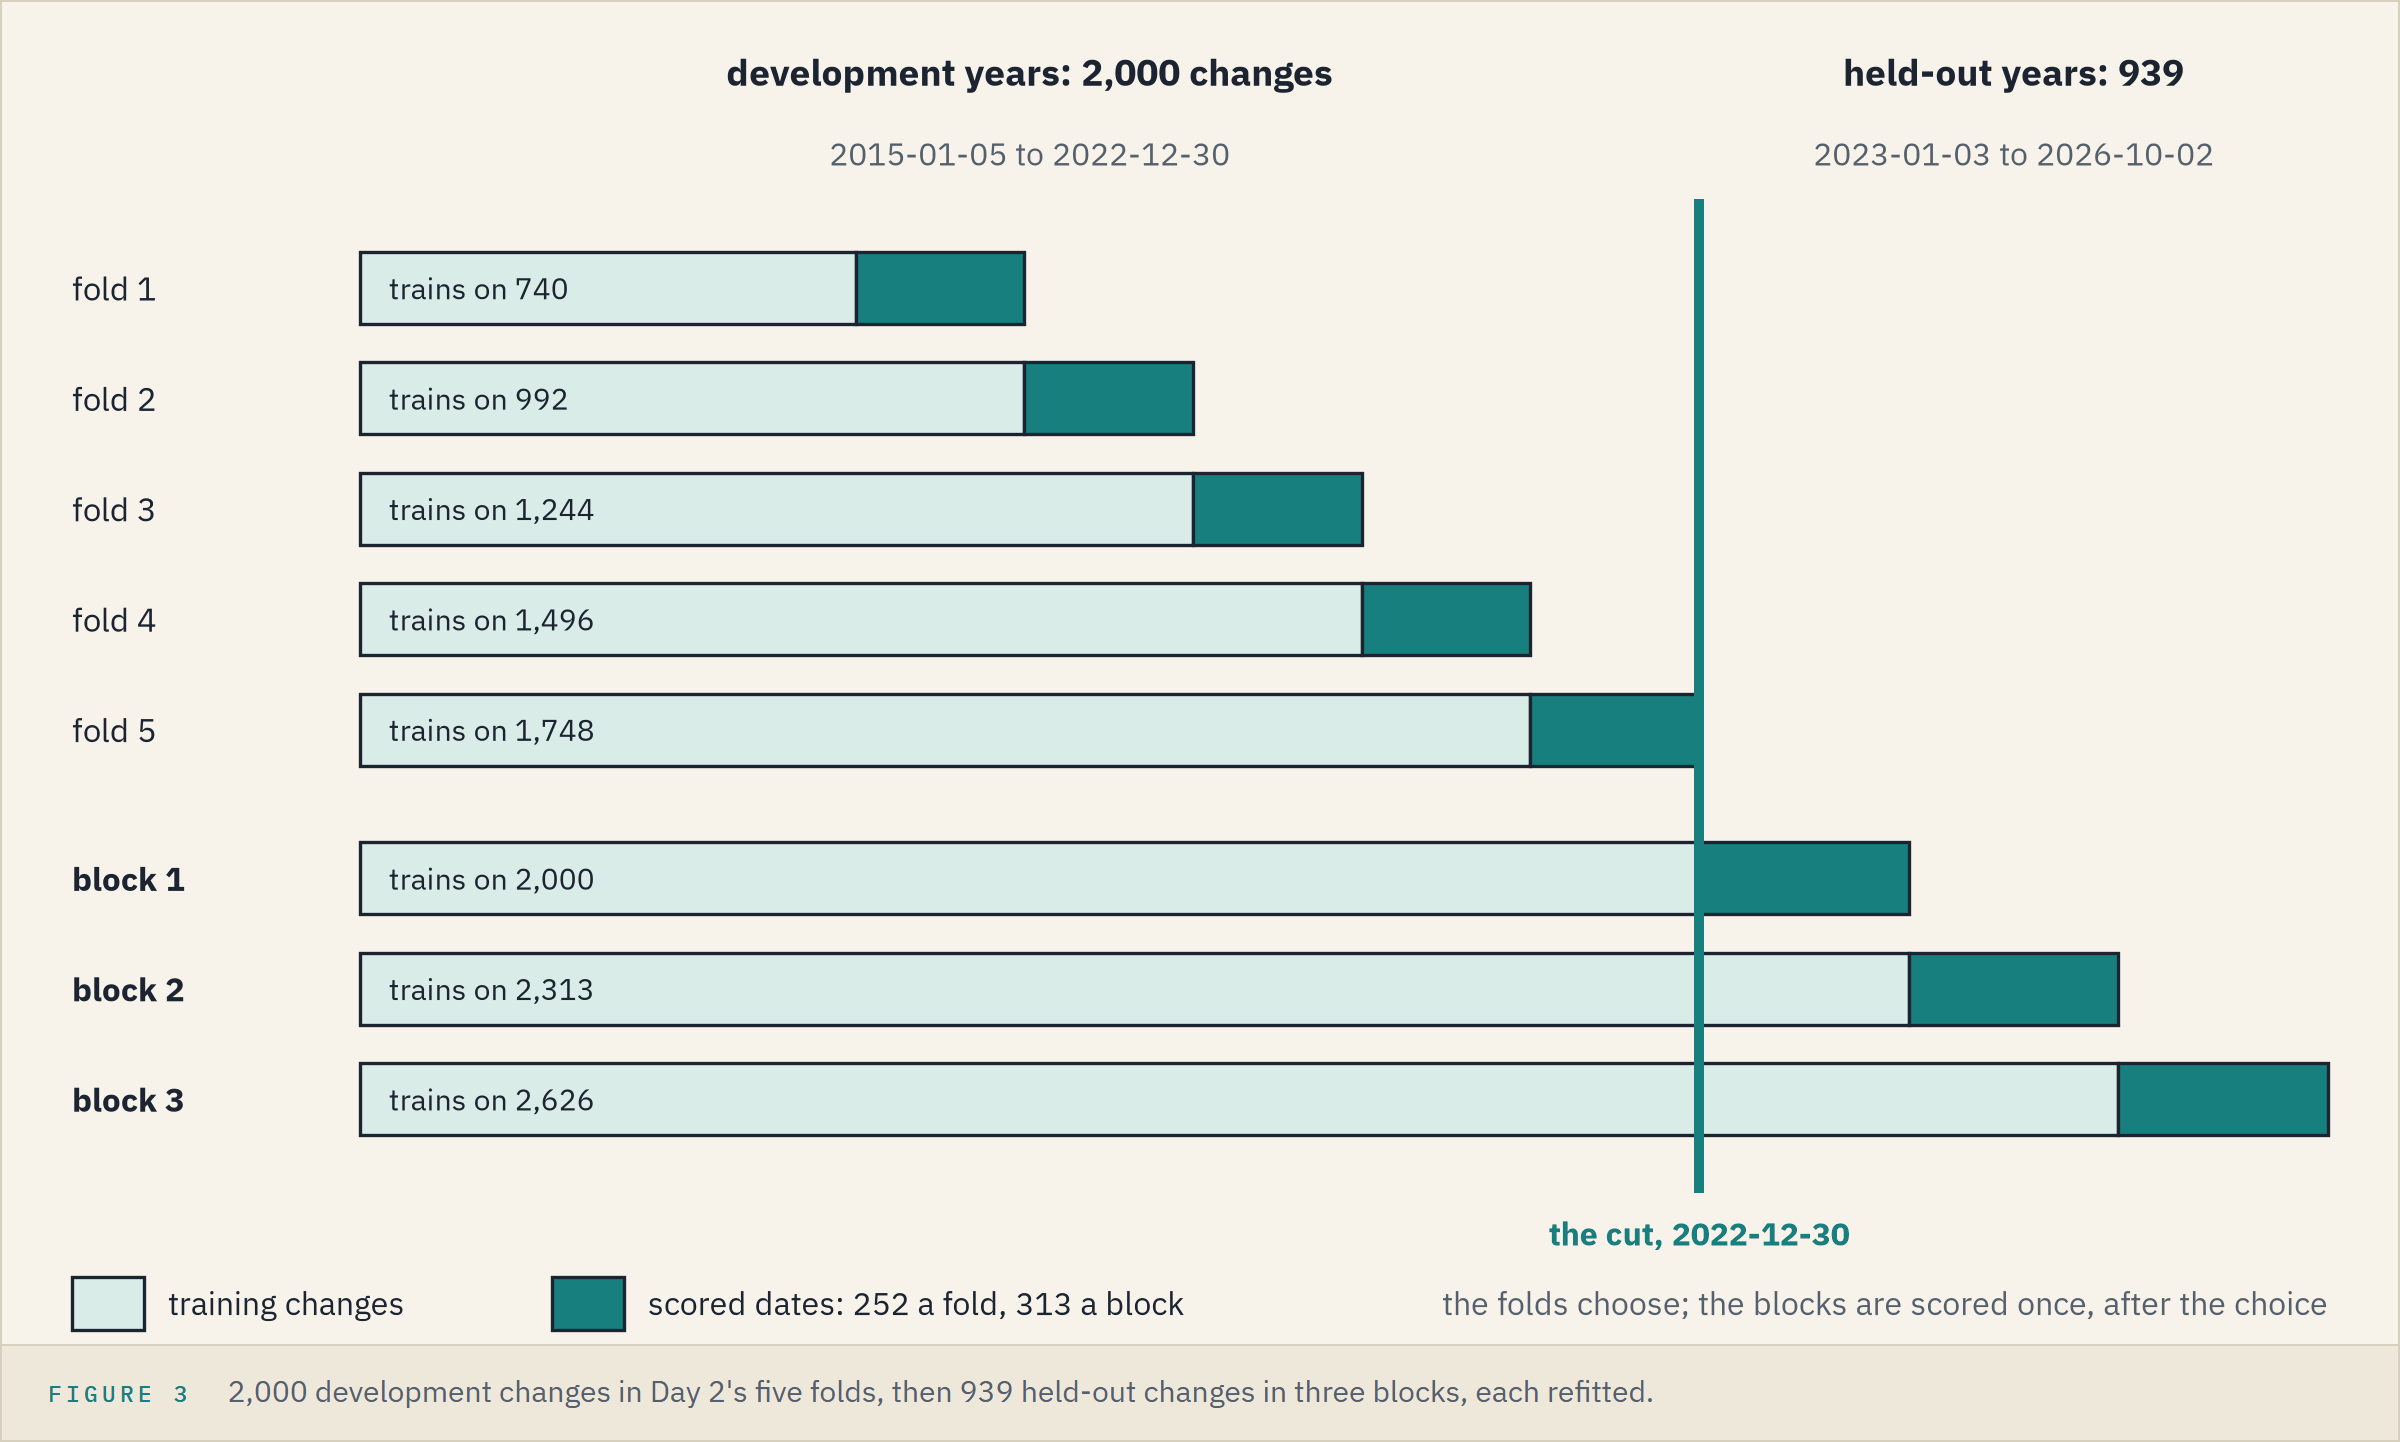

## Lag Features That Pass the Cut Test

Day 8's fifteen features: lags 1, 2 and 5, the mean, sd and mean size of the 5 and 20 changes before, the other series' lag 1, the weekday and the month.

Q. Write Day 8's `lag_features(changes, name)`, and keep each series' features in a dictionary `features`, the first 20 rows dropped once. Run Day 2's strict cut test at 2019-12-31 on the 2s10s's. Store the columns, the rows, and the columns equal at the cut in `q9_columns`, `q9_rows` and `q9_equal`.

In [28]:
# your code here
q9_columns = ...
q9_rows = ...
q9_equal = ...

In [29]:
check("Q9 columns", q9_columns, "be97169d3993", places=0)
check("Q9 rows", q9_rows, "b7e391ab1c3b", places=0)
check("Q9 columns equal at the cut", q9_equal, "bfc9ac7a9162", places=0)

Q9 columns: not attempted yet
Q9 rows: not attempted yet
Q9 columns equal at the cut: not attempted yet


**Every input uses only earlier dates, and the folds are Day 2's.**

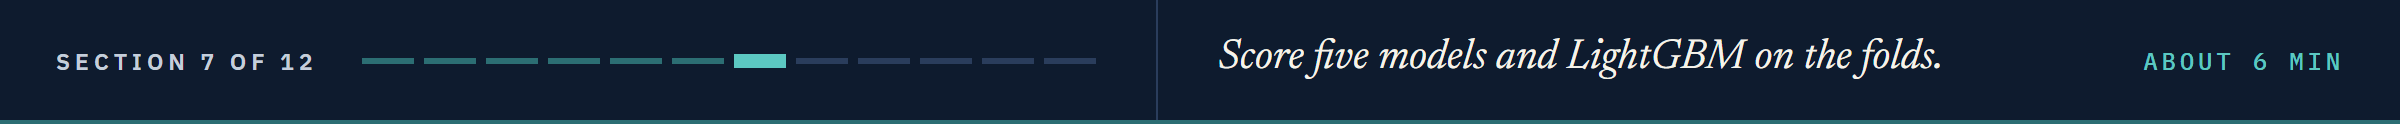

# Modeling the Change

## Scoring a Model

`walk_forward` is Day 2's loop as one function.
`make_values(train, test)` fits on a split's training changes and returns a value for each test date: the last value's is `lambda train, test: 0 * test`.
`size=True` scores against the size of each change.

In [30]:
def walk_forward(data, splits, make_values, size=False):
    """Each split's MAE in bp, and the values on its test dates; size=True scores them against the size of the change."""
    maes, values = [], []
    for fit_rows, test_rows in splits:
        train, test = data.iloc[fit_rows], data.iloc[test_rows]
        values.append(pd.Series(np.asarray(make_values(train, test)), index=test.index))
        maes.append(mean_absolute_error(test.abs() if size else test, values[-1]))
    return pd.Series(maes, index=range(1, len(splits) + 1)), pd.concat(values)

Day 5's ARIMA as a value maker, run on through the test dates with `.append()`.

In [31]:
# Day 5's one-step values from an ARIMA; each fit's convergence is kept in a list
converged = []
def arima_values(train, test, order):
    """One-step values on the test dates from an ARIMA(p, 0, q) fitted on the training changes."""
    # a mixed order: statsmodels' first guess for its AR and MA terms may not be usable, so it warns and starts from zeros
    with warnings.catch_warnings():
        warnings.simplefilter("ignore", EstimationWarning)
        fit = ARIMA(train.to_numpy(), order=order, trend="c").fit(method_kwargs={"warn_convergence": False})
    converged.append(fit.mle_retvals["converged"])
    return fit.append(test.to_numpy(), refit=False).predict(start=len(train), end=len(train) + len(test) - 1)

## How Many Terms

Q. Fit `ARIMA(p, 0, q)`, p and q from 0 to 2, on fold 1's training changes, a table `grid` of BIC. Store each series' lowest (p, q), as a tuple, in `q10_2s10s` and `q10_hy`.

In [32]:
# your code here
q10_2s10s = ...
q10_hy = ...

In [33]:
check("Q10 2s10s order", q10_2s10s, "ced9cbe3d554")
check("Q10 HY order", q10_hy, "f73acffd8d90")

Q10 2s10s order: not attempted yet
Q10 HY order: not attempted yet


## ARIMA and Smoothing

Day 6's smoothing fits alpha on the training levels; its one-step value is the EWMA through the row before.
A fitted change ignores a constant added to the level, so `.cumsum()` of the changes serves as the level.

Q. Score the last value, drift, AR(1), ARMA(1, 1) and smoothing on the folds, a table of fold MAEs per series in `change_mae`, and their MASEs in `mase`. Store the 2s10s's for AR(1) and smoothing, and the HY's for ARMA(1, 1), in `q11_ar`, `q11_smoothing` and `q11_hy_arma` (4 decimals).

In [34]:
# your code here
q11_ar = ...
q11_smoothing = ...
q11_hy_arma = ...

In [35]:
check("Q11 2s10s AR(1) MASE", q11_ar, "877c001f646a", places=4)
check("Q11 2s10s smoothing MASE", q11_smoothing, "fa60a1758c91", places=4)
check("Q11 HY ARMA(1, 1) MASE", q11_hy_arma, "5a5bfee421ca", places=4)

Q11 2s10s AR(1) MASE: not attempted yet
Q11 2s10s smoothing MASE: not attempted yet
Q11 HY ARMA(1, 1) MASE: not attempted yet


## LightGBM on Lags

Day 8 fitted LightGBM on the training dates with all fifteen features, from 2015-02-03.
Day 8's chosen setting: `learning_rate=0.01, n_estimators=25, num_leaves=2, min_child_samples=20`.

Q. Write `lgbm_values(train, test, **settings)` on `features[train.name]`, and add LightGBM's defaults and Day 8's setting to `change_mae` and `mase`. Store their MASEs on the HY in `q12_defaults` and `q12_day8` (4 decimals).

Q. Draw each fold's MAE over the last value's, one row per model and series, the mean a diamond.

In [36]:
# your code here
q12_defaults = ...
q12_day8 = ...

# then your chart

In [37]:
check("Q12 HY LightGBM defaults MASE", q12_defaults, "c4e530cce687", places=4)
check("Q12 HY LightGBM Day 8 MASE", q12_day8, "7987c3382474", places=4)

Q12 HY LightGBM defaults MASE: not attempted yet
Q12 HY LightGBM Day 8 MASE: not attempted yet


**On the change, every model sits within a hair of the last value or behind it.**

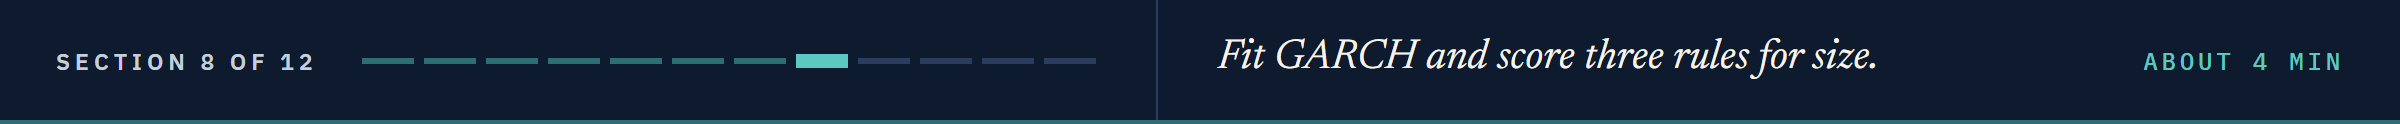

# Modeling the Size

Days 6 and 7 scored a rule for the size of a change, `abs()` in bp, by MAE.
A GARCH volatility is a standard deviation; for a normal shock the average size is sqrt(2 / pi), about 0.798, times it, so 0.798 times GARCH's volatility is its value for the size (Day 7).

**Predict 2**

Day 7 fitted GARCH(1, 1) to the true 2s10s's 2,000 changes: persistence 0.9936, a half-life of 107 rows.
Your repaired copy differs from the true values in a few cells.

Q. What half-life will the same fit give on the repaired 2s10s? Write down a number of rows.

## GARCH on the Development Years

Q. Fit Day 7's GARCH(1, 1) on all 2,000 changes of each series, keeping alpha, beta, persistence and half-life in `garch_table`. Store the 2s10s's persistence and half-life and the HY's half-life in `q13_persistence`, `q13_half_life` and `q13_hy_half_life` (4 decimals; 1 for half-lives).

In [38]:
# your code here
q13_persistence = ...
q13_half_life = ...
q13_hy_half_life = ...

In [39]:
check("Q13 2s10s persistence", q13_persistence, "b8700134f205", places=4)
check("Q13 2s10s half-life", q13_half_life, "6962f6bae4f8", places=1)
check("Q13 HY half-life", q13_hy_half_life, "ff5311a64e6f", places=1)

Q13 2s10s persistence: not attempted yet
Q13 2s10s half-life: not attempted yet
Q13 HY half-life: not attempted yet


## Three Rules for the Size

The three: the training mean of the size (a constant), Day 6's EWMA of the size at lambda 0.94, and GARCH fitted once a fold.
`model.fix(params)` runs an arch model with fixed numbers: its `.conditional_volatility` on a test date reads only the rows before it.

Q. Score the three with `walk_forward(..., size=True)`: fold MAEs in `size_mae`, values in `size_values`, a table per series. Store GARCH's average MAE over the constant's on each series in `q14_2s10s` and `q14_hy` (4 decimals), and the HY folds where GARCH is closer in `q14_hy_folds`.

A **Bland-Altman plot** compares two measures of the same thing: each date's difference against their mean, with the mean difference and plus and minus 1.96 standard deviations of it drawn across.

Q. Draw GARCH's value and the EWMA's over the HY's sizes in fold 5, and a Bland-Altman plot of the two.

In [40]:
# your code here
q14_2s10s = ...
q14_hy = ...
q14_hy_folds = ...

# then your chart

In [41]:
check("Q14 2s10s GARCH over the constant", q14_2s10s, "0d5d154b3355", places=4)
check("Q14 HY GARCH over the constant", q14_hy, "3878a0f9e070", places=4)
check("Q14 HY folds GARCH closer", q14_hy_folds, "a00c7111f822", places=0)

Q14 2s10s GARCH over the constant: not attempted yet
Q14 HY GARCH over the constant: not attempted yet
Q14 HY folds GARCH closer: not attempted yet


**GARCH is closer than a constant on the HY in every fold, by less than the folds disagree.**

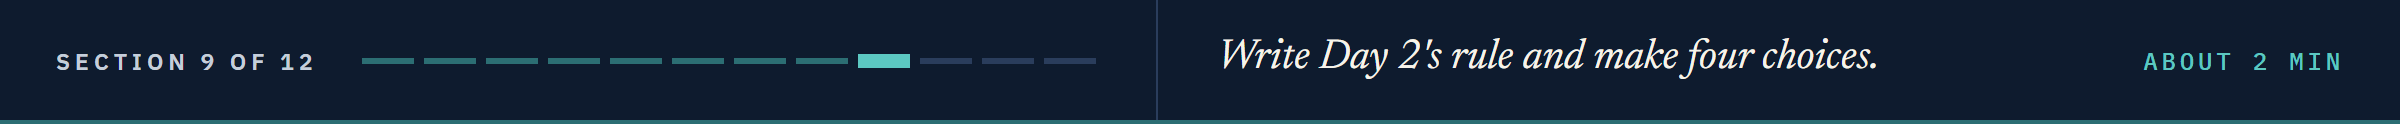

# Final Model Selection

Every model has a score on the five development folds, and Day 2's rule picks from them.

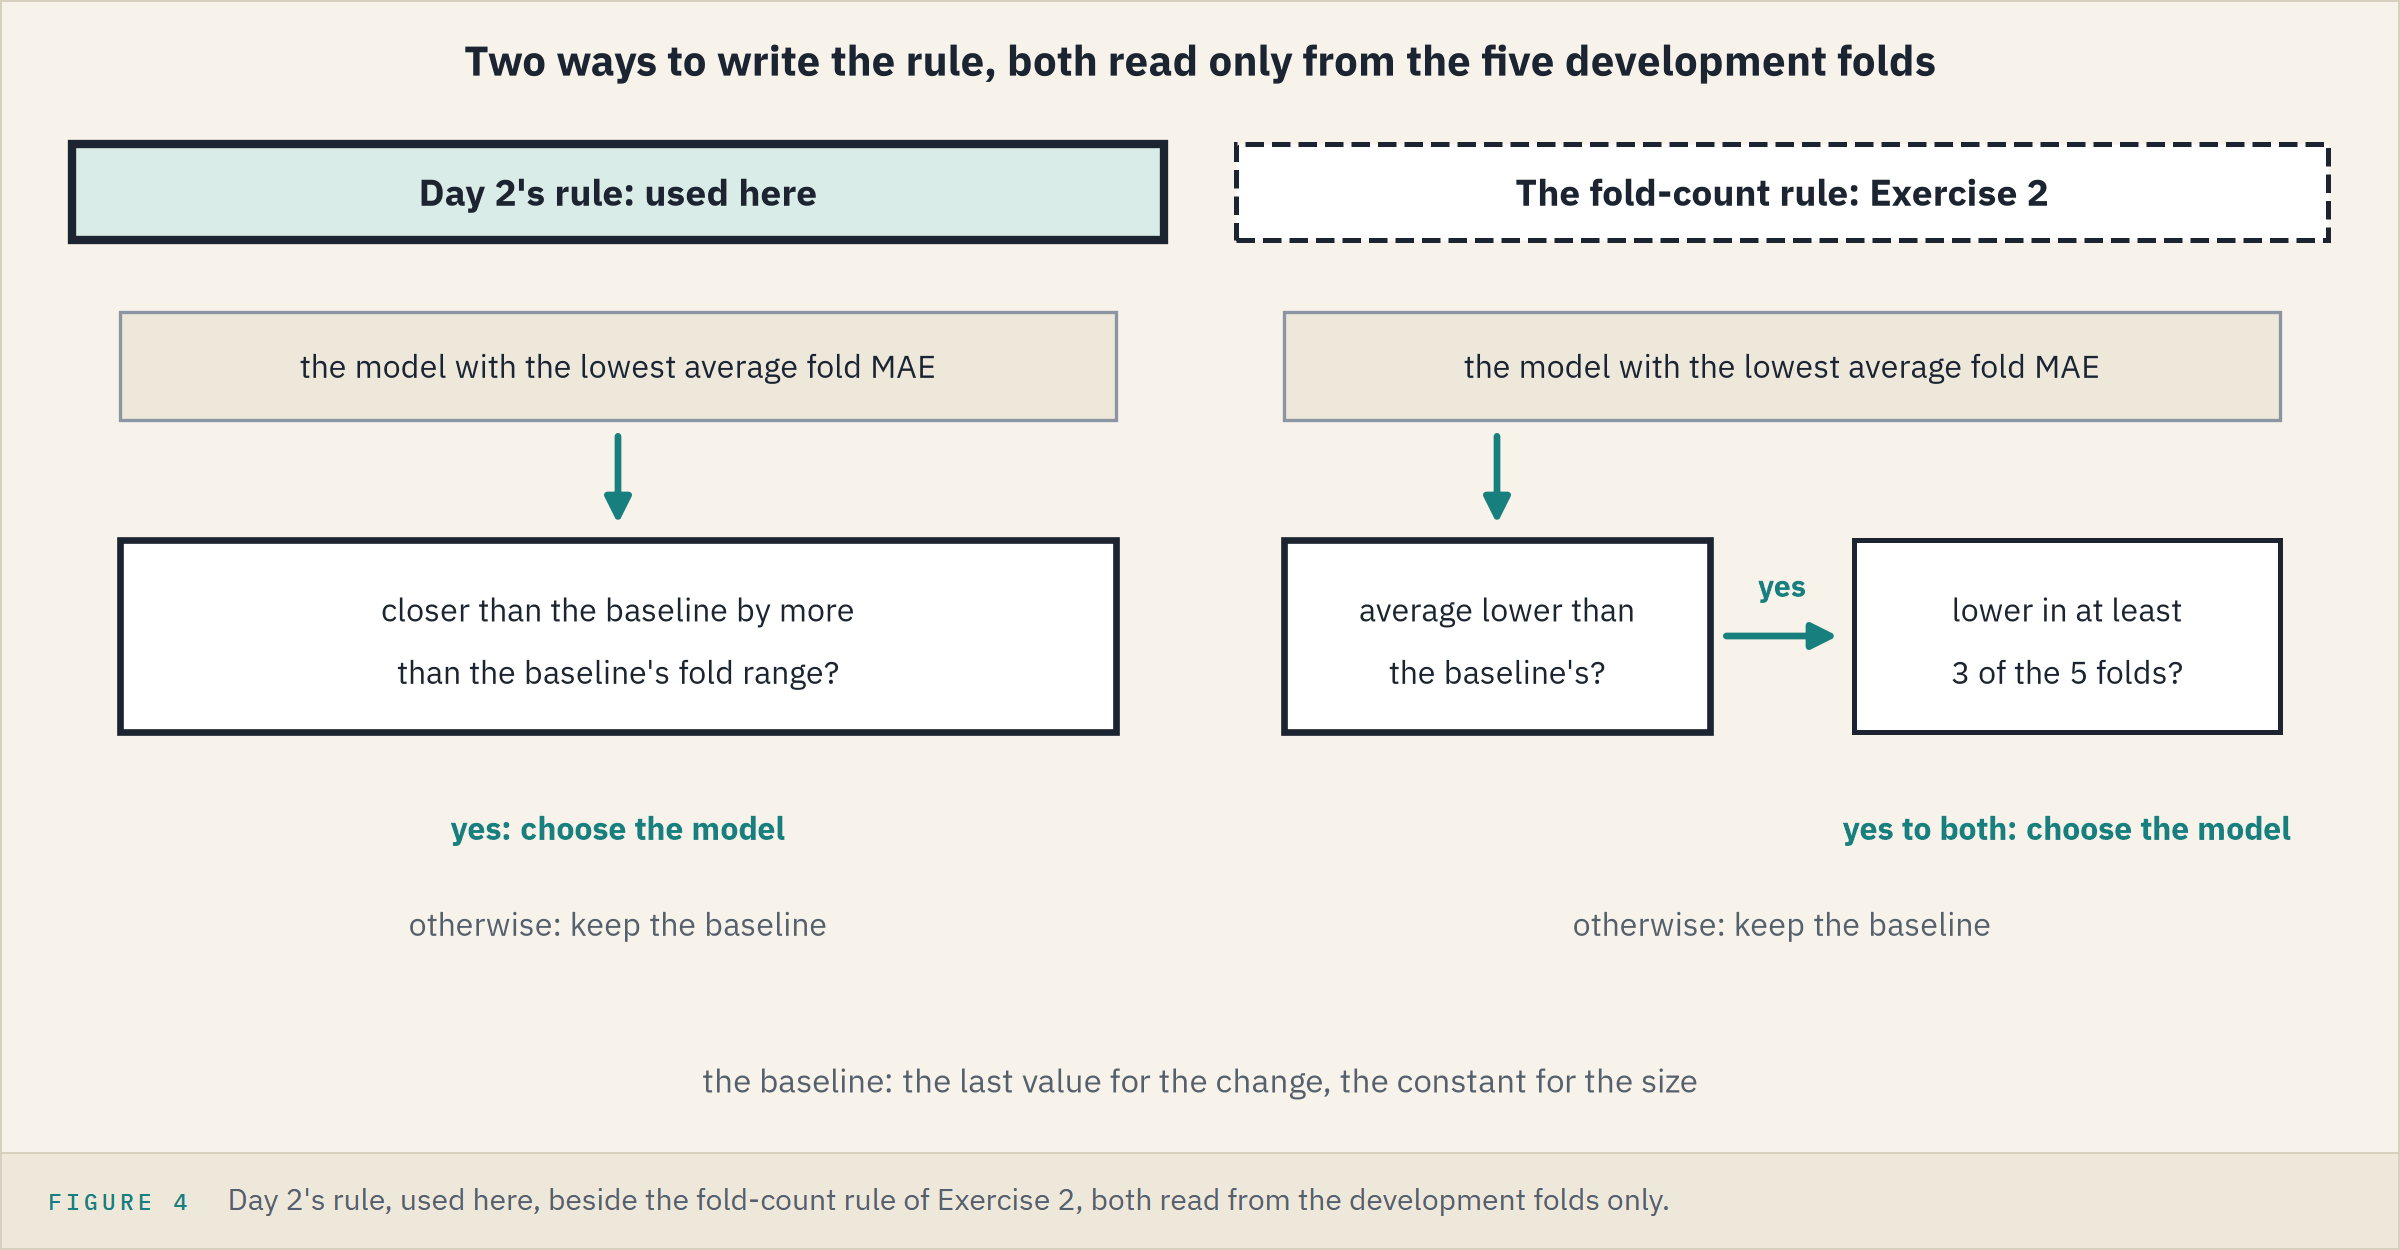

## The Rule, Written First

Q. Write Day 2's rule as `choose(fold_mae, baseline)`, and apply it to `change_mae` and `size_mae`, in a dictionary `choice` keyed `("2s10s", "change")` and so on. Store the four choices in `q15_change_2s10s`, `q15_change_hy`, `q15_size_2s10s` and `q15_size_hy`.

In [42]:
# your code here
q15_change_2s10s = ...
q15_change_hy = ...
q15_size_2s10s = ...
q15_size_hy = ...

In [43]:
check("Q15 2s10s change", q15_change_2s10s, "a2892745abfe")
check("Q15 HY change", q15_change_hy, "852de1167ae2")
check("Q15 2s10s size", q15_size_2s10s, "6acea71ed7ef")
check("Q15 HY size", q15_size_hy, "15b3e90d03fa")

Q15 2s10s change: not attempted yet
Q15 HY change: not attempted yet
Q15 2s10s size: not attempted yet
Q15 HY size: not attempted yet


**The choice is fixed before one held-out value is read.**

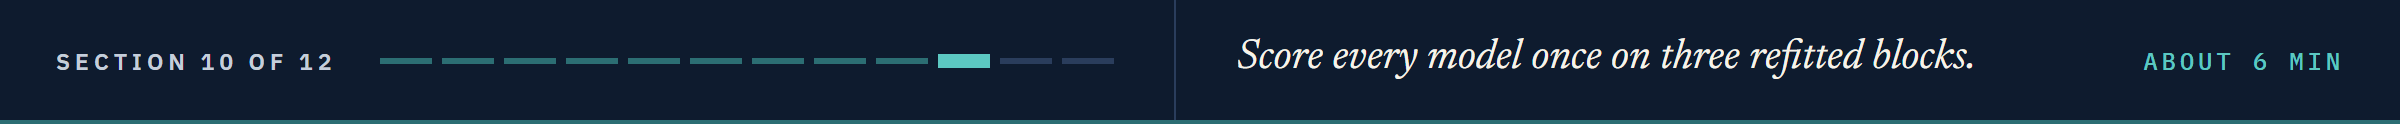

# The Held-Out Years, Opened Once

## Opening Them

The cell below reads the held-out years, once: Day 2's five series in bp for the 939 dates after the cut.

In [44]:
# the held-out years, read once: the five series in bp, as Day 2 made them
held_out = yields.loc[yields.index > CUT]
held_levels = pd.DataFrame({"2 Yr": (held_out["2 Yr"] * 100).round(2), "10 Yr": (held_out["10 Yr"] * 100).round(2),
                            "2s10s": ((held_out["10 Yr"] - held_out["2 Yr"]) * 100).round(2),
                            "IG": spreads.loc[held_out.index, "ig_spread_bp"], "HY": spreads.loc[held_out.index, "hy_spread_bp"]})
print(len(held_levels), "dates,", held_levels.index[0].date(), "to", held_levels.index[-1].date(), "| blank cells:", held_levels.isna().sum().sum())

939 dates, 2023-01-03 to 2026-10-02 | blank cells: 0


Each held-out block is scored as a fold was, by a model refitted on every change before it.
`TimeSeriesSplit(n_splits=3, test_size=313)` makes three blocks of 313.

Q. Join `held_levels` under `levels`, make `full_changes` and the `blocks`, and rebuild `features` on `full_changes`. Store the number of changes, the last date of the first block and the first of the third (`YYYY-MM-DD`) in `q16_changes`, `q16_first_end` and `q16_third_start`.

In [45]:
# your code here
q16_changes = ...
q16_first_end = ...
q16_third_start = ...

In [46]:
check("Q16 changes", q16_changes, "a5c92b692484", places=0)
check("Q16 end of the first block", q16_first_end, "bc1fbf2cfd38")
check("Q16 start of the third block", q16_third_start, "669f59e26a35")

Q16 changes: not attempted yet
Q16 end of the first block: not attempted yet
Q16 start of the third block: not attempted yet


**Predict 3**

On the five development folds the last value missed the 2s10s's change by 2.571 bp a date.

Q. What will its MAE be on the 939 held-out dates? Write down a number in bp.

## The Change, Scored Once

Q. Walk every change model over the blocks: block MAEs in `held_change`, MASEs in `held_mase`. Store the last value's held-out MAE on each series in `q17_last_2s10s` and `q17_last_hy` (4 decimals), and the models closer than it on the 2s10s in `q17_closer`.

Q. Draw each model's MASE on the folds and on the blocks as a dumbbell.

In [47]:
# your code here
q17_last_2s10s = ...
q17_last_hy = ...
q17_closer = ...

# then your chart

In [48]:
check("Q17 2s10s last value", q17_last_2s10s, "ff226d036a7f", places=4)
check("Q17 HY last value", q17_last_hy, "3cb66cb6f463", places=4)
check("Q17 models closer on the 2s10s", q17_closer, "b02bd077b3f6", places=0)

Q17 2s10s last value: not attempted yet
Q17 HY last value: not attempted yet
Q17 models closer on the 2s10s: not attempted yet


**Predict 4**

On the HY's five development folds GARCH missed the size by 0.942 of the constant's MAE, closer in every fold.

Q. What will that ratio be on the 939 held-out dates? Write down a number.

## The Size, Scored Once

Q. Walk the size rules over the blocks: `held_size` and `held_size_values`. Store GARCH's held-out ratio to the constant on each series in `q18_2s10s` and `q18_hy` (4 decimals), and the HY dates where GARCH is closer in `q18_hy_dates`.

A **rolling relative error** curve divides one rule's MAE over a moving window by another's: below 1 the first is closer.

Q. Draw that curve for GARCH over the constant, 63 dates wide, with the block edges and the development ratio marked.

In [49]:
# your code here
q18_2s10s = ...
q18_hy = ...
q18_hy_dates = ...

# then your chart

In [50]:
check("Q18 2s10s GARCH over the constant", q18_2s10s, "590912aa80dd", places=4)
check("Q18 HY GARCH over the constant", q18_hy, "cbc044f20309", places=4)
check("Q18 HY dates GARCH closer", q18_hy_dates, "2e0386758367", places=0)

Q18 2s10s GARCH over the constant: not attempted yet
Q18 HY GARCH over the constant: not attempted yet
Q18 HY dates GARCH closer: not attempted yet


**Both choices held, and GARCH's development gain on the size mostly did not carry over.**

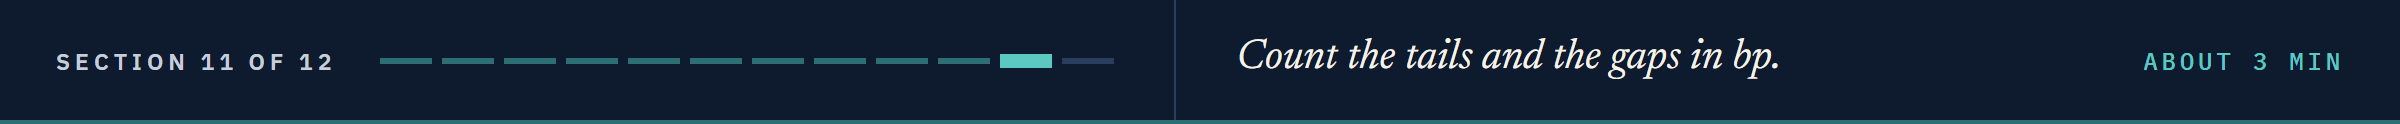

# Where the Misses Fall

## Tails GARCH Leaves

GARCH's volatility on a date is its value for the size over 0.798.
A normal curve puts about 2.5 of 939 draws beyond 3.

Q. Divide each held-out change by it, in a dictionary `units`. Store how many lie beyond 3 on each series in `q19_2s10s` and `q19_hy`.

A **hanging rootogram** hangs each bin's square-root count from a normal curve's: a bar ending above zero is a bin with too few, below zero too many.

Q. Draw one per series, bins of half a volatility.

A **wedge plot** draws each change against its volatility, with rays at plus and minus 3 volatilities: a date outside the wedge is one a normal curve almost never holds.

Q. Draw one per series, the dates outside the wedge marked.

In [51]:
# your code here
q19_2s10s = ...
q19_hy = ...

# then your chart

In [52]:
check("Q19 2s10s beyond 3", q19_2s10s, "c6fac6db6802", places=0)
check("Q19 HY beyond 3", q19_hy, "68cdc93bddd3", places=0)

Q19 2s10s beyond 3: not attempted yet
Q19 HY beyond 3: not attempted yet


## The Gaps in bp

Q. Keep each model's held-out MAE less the last value's, in bp, in `held_gap`. Store the HY's largest and its model in `q20_gap` (4 decimals) and `q20_model`.

Q. Draw them as bars, with a band of plus and minus the last value's development fold range.

In [53]:
# your code here
q20_gap = ...
q20_model = ...

# then your chart

In [54]:
check("Q20 largest HY gap", q20_gap, "7a545ad2b534", places=4)
check("Q20 its model", q20_model, "76c5678cb4b3")

Q20 largest HY gap: not attempted yet
Q20 its model: not attempted yet


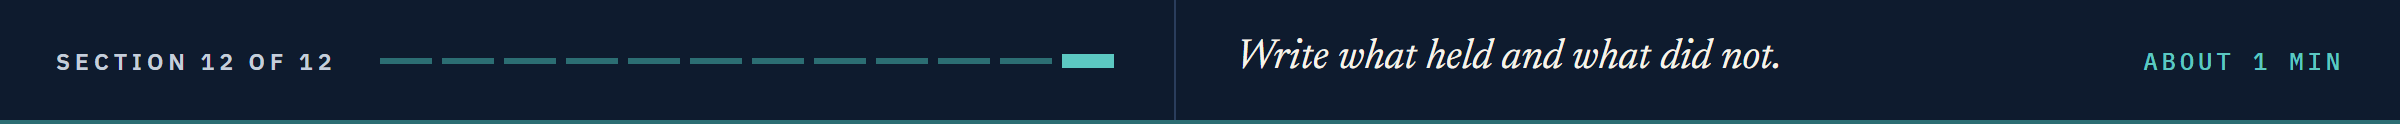

# Insights and Conclusion

## The Description

Q. Write `description`, a few sentences: the repair, the rule, what held on the held-out years and what did not, and what was not tested.

In [55]:
# your code here
description = ...

**A model describes the dates it was scored on.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Repair a dated copy with a corrections table, a change log and a capped fill, and check the repair against held-back values.
* Test a series for a unit root and read the memory in its changes and in their size.
* Score models of a change and of its size over walk-forward folds with one function.
* Write a choice rule before scoring held-out dates, and open them once, refitting block by block.
* Draw a Bland-Altman plot, a hanging rootogram and a wedge plot of changes against their volatility.

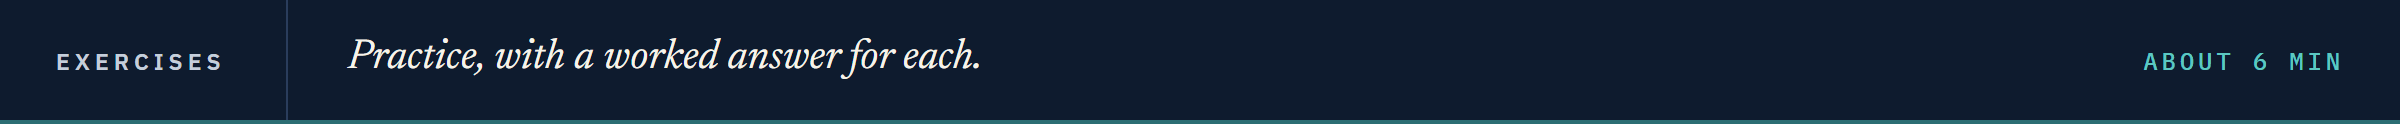

## Exercises

**Every exercise has a worked answer** in the solutions notebook in this folder: the one with this notebook's name ending in `_solutions.ipynb`.

Give each exercise a real try first, then check your work against it.

`check()` from Setting Up marks each answer.

### Exercise 1

**One Fit for All 939 Dates**

Q. Score the held-out years with one split, `[(np.arange(2000), np.arange(2000, 2939))]`: one fit, its numbers held for 939 dates. Store GARCH's ratio to the constant on the HY and the ARMA(1, 1)'s MASE on the 2s10s in `ex1_garch_hy` and `ex1_arma_2s10s` (4 decimals).

In [56]:
# your code here
ex1_garch_hy = ...
ex1_arma_2s10s = ...

In [57]:
check("Exercise 1 HY GARCH, one fit", ex1_garch_hy, "8870d64bc6eb", places=4)
check("Exercise 1 2s10s ARMA(1, 1), one fit", ex1_arma_2s10s, "430beb13dbfe", places=4)

Exercise 1 HY GARCH, one fit: not attempted yet
Exercise 1 2s10s ARMA(1, 1), one fit: not attempted yet


### Exercise 2

**Another Rule**

Q. Write `choose_by_folds(fold_mae, baseline, min_folds=3)`: the lowest-average model if it beats the baseline on average and in at least `min_folds` folds. Store how many of the four choices differ from `choice`, and its HY size choice, in `ex2_changed` and `ex2_size_hy`.

In [58]:
# your code here
ex2_changed = ...
ex2_size_hy = ...

In [59]:
check("Exercise 2 choices that differ", ex2_changed, "bb29d728fdb8", places=0)
check("Exercise 2 HY size", ex2_size_hy, "878d629dbb30")

Exercise 2 choices that differ: not attempted yet
Exercise 2 HY size: not attempted yet


Optional, with Course 3's FRED key: run the same workflow on an ICE BofA spread series on your own screen.
Licensed series are never saved or shared (Course 3).

### Exercise 3: AI check

**A MASE That Is Not One**

You asked an AI assistant for a function that turns block MAEs into MASEs.
This came back.
It runs.
Test it, then find the one bug.

In [60]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def mase_by_model(mae_table):
    """Each model's MASE: its average MAE over the last value's, so the last value scores exactly 1."""
    average = mae_table.mean()
    return average / average.min()

In [61]:
# the test: on a small table of block MAEs in bp, the last value's MASE must be exactly 1
example = pd.DataFrame({"last value": [2.9, 3.1, 2.8], "drift": [2.9, 3.2, 2.8], "smoothing": [2.8, 3.1, 2.8]})
ai_mase = mase_by_model(example)
assert ai_mase["last value"] == 1, f"the last value scores {ai_mase['last value']:.4f}"

AssertionError: the last value scores 1.0115

Q. Fix the function so it divides by the last value's average. Store the fixed MASE of smoothing on the held-out 2s10s in `ex3_smoothing` (4 decimals).

In [62]:
# your code here
ex3_smoothing = ...

In [63]:
check("Exercise 3 smoothing MASE", ex3_smoothing, "ae6493c229b7", places=4)

Exercise 3 smoothing MASE: not attempted yet


## Congratulations!

You ran the whole course on a copy nobody had cleaned for you, and the work was yours.
You repaired it with a log, scored every model on folds, and fixed the choice before the held-out years were read.
Then you opened them once and said plainly what held and what did not.
Course 5C turns to risk models, Monte Carlo and survival curves, on the same habits.

[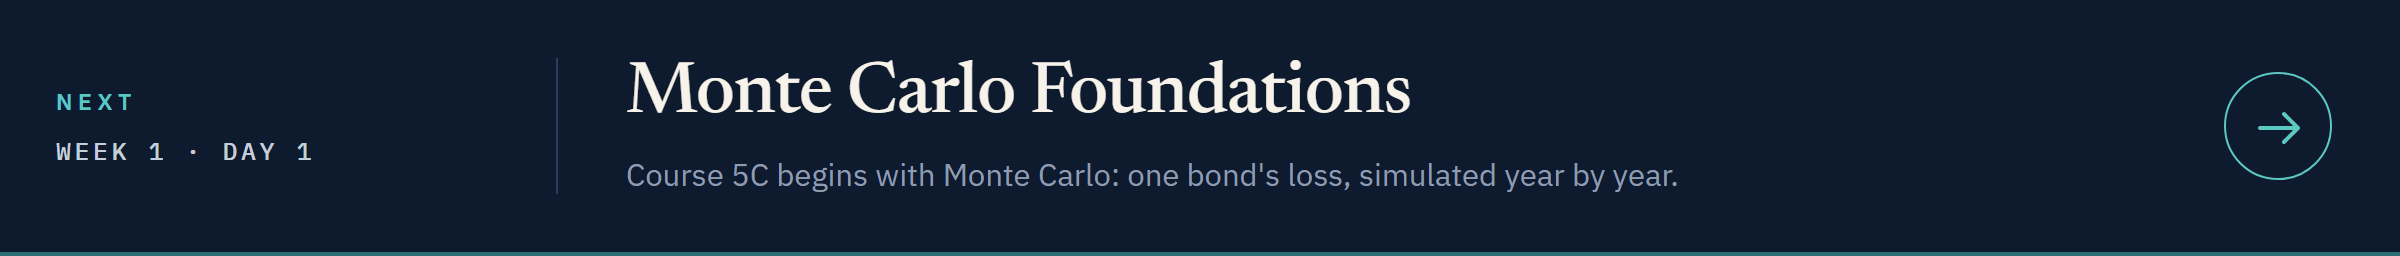](../../../course05c_risk_models/week1/day1/01_monte_carlo_foundations.ipynb)

[Open Day 1 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05c_risk_models/week1/day1/01_monte_carlo_foundations.ipynb)